In [3]:
import pandas as pd
import numpy as np

import seaborn as sns
from matplotlib import pyplot as plt
%matplotlib inline

In [45]:
from sklearn.model_selection import train_test_split

In [5]:
df = pd.read_csv('course_lead_scoring_2026.csv')
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [6]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

In [27]:
for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = df[col].fillna('NA')
    else:
        df[col] = df[col].fillna(0)

df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [29]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [30]:
df_train

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
4740,paid_ads,technology,employed,asia,80198.0,5,9,0.91,1
1452,paid_ads,retail,employed,asia,50548.0,2,5,0.48,0
2846,NA,finance,employed,NA,76300.0,0,3,0.42,0
4670,paid_ads,finance,employed,NA,80371.0,2,6,0.49,0
168,organic_search,finance,employed,asia,73567.0,2,4,0.48,1
...,...,...,...,...,...,...,...,...,...
253,paid_ads,finance,employed,north_america,84573.0,2,3,0.37,1
1366,events,technology,employed,asia,85051.0,1,3,0.56,0
753,events,retail,unemployed,asia,21561.0,0,1,0.17,0
4990,organic_search,healthcare,unemployed,south_america,31691.0,3,5,0.49,1


# Question 1: ROC AUC feature importance

In [32]:
numerical_features = []
for col in df.columns:
    if df[col].dtype != 'object' and col != 'converted':
        numerical_features.append(col)

numerical_features

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [41]:
from sklearn.metrics import roc_auc_score

for col in numerical_features:
    auc = roc_auc_score(df["converted"], df[col])

    if auc < 0.5:
        auc = 1 - auc
        
    print('Feature: %s -> AUC: %f' %(col, auc))

Feature: annual_income -> AUC: 0.609792
Feature: number_of_courses_viewed -> AUC: 0.722849
Feature: interaction_count -> AUC: 0.762357
Feature: lead_score -> AUC: 0.787228


In [42]:
from sklearn.metrics import roc_auc_score

features = ["age", "income", "balance", "tenure"]

for col in numerical_features:
    auc = roc_auc_score(df["converted"], df[col])

    if auc < 0.5:
        auc = roc_auc_score(-df["converted"], df[col])

    print(f'Feature: {col} -> AUC: {auc}')

Feature: annual_income -> AUC: 0.60979163604804
Feature: number_of_courses_viewed -> AUC: 0.7228486308497142
Feature: interaction_count -> AUC: 0.7623573499695493
Feature: lead_score -> AUC: 0.7872284404317591


# Question 2: Training the model

In [44]:
df_train

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
4740,paid_ads,technology,employed,asia,80198.0,5,9,0.91,1
1452,paid_ads,retail,employed,asia,50548.0,2,5,0.48,0
2846,NA,finance,employed,NA,76300.0,0,3,0.42,0
4670,paid_ads,finance,employed,NA,80371.0,2,6,0.49,0
168,organic_search,finance,employed,asia,73567.0,2,4,0.48,1
...,...,...,...,...,...,...,...,...,...
253,paid_ads,finance,employed,north_america,84573.0,2,3,0.37,1
1366,events,technology,employed,asia,85051.0,1,3,0.56,0
753,events,retail,unemployed,asia,21561.0,0,1,0.17,0
4990,organic_search,healthcare,unemployed,south_america,31691.0,3,5,0.49,1


In [46]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

y_train = df_train['converted']
y_val = df_val['converted']
y_text = df_test['converted']

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [47]:
train_dict = df_train.to_dict(orient='records')
val_dict = df_val.to_dict(orient='records')
test_dict = df_test.to_dict(orient='records')

dv = DictVectorizer(sparse=False)
dv.fit(train_dict)

X_train = dv.transform(train_dict)
X_val = dv.transform(val_dict)
X_test = dv.transform(test_dict)
X_train[0]

array([8.0198e+04, 0.0000e+00, 1.0000e+00, 0.0000e+00, 0.0000e+00,
       0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
       0.0000e+00, 0.0000e+00, 1.0000e+00, 9.0000e+00, 9.1000e-01,
       0.0000e+00, 0.0000e+00, 0.0000e+00, 1.0000e+00, 0.0000e+00,
       0.0000e+00, 0.0000e+00, 0.0000e+00, 1.0000e+00, 0.0000e+00,
       0.0000e+00, 0.0000e+00, 5.0000e+00])

In [48]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model

LogisticRegression(max_iter=1000, solver='liblinear')

In [49]:
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000, solver='liblinear')

In [58]:
from sklearn.metrics import auc, roc_auc_score, roc_curve

y_pred = model.predict_proba(X_val)[:, 1]
fpr, tpr, thresholds = roc_curve(y_val, y_pred)

round(auc(fpr, tpr), 3)

0.732

# Question 3: Precision and Recall

In [76]:
from sklearn.metrics import precision_score, recall_score

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

thresholds = np.arange(0, 1, 0.01) 
precision = []
recall = []
for t in thresholds:
    y_pred_threshold  = model.predict_proba(X_val)[:, 1]

    y_pred = (y_pred_threshold>=t).astype(int)
    
    precision.append(precision_score(y_val, y_pred, zero_division=0))
    recall.append(recall_score(y_val, y_pred, zero_division=0))

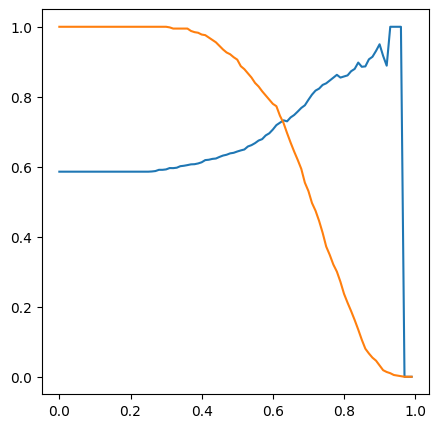

In [82]:
plt.figure(figsize=(5, 5))

plt.plot(thresholds, precision, label='precision')
plt.plot(thresholds, recall, label='recall')
plt.show()

In [87]:
min_diff = 1000
for n in range(len(precision)):
    diff = abs(precision[n] - recall[n])
    if diff < min_diff:
        min_diff = diff
        best_threshold = thresholds[n]
        print(min_diff, best_threshold)

0.41400000000000003 0.0
0.4134134134134134 0.26
0.4122367101303912 0.27
0.408678102926337 0.28
0.40748230535894847 0.3
0.401963240129004 0.31
0.39876602664768246 0.32
0.39754448050131486 0.33
0.3932293592845797 0.34
0.3919849928175879 0.35000000000000003
0.39010876184272025 0.36
0.3811363685148218 0.37
0.3772732171726244 0.38
0.37341134405980814 0.39
0.36498147505977263 0.4
0.35706159596944576 0.41000000000000003
0.34919594020597045 0.42
0.33994078159256835 0.43
0.3320233815000342 0.44
0.31727457763537725 0.45
0.3030889930756483 0.46
0.29227536601703297 0.47000000000000003
0.2832038341442161 0.48
0.2730171301664027 0.49
0.262506981073534 0.5
0.2406058444976482 0.51
0.22940705576524967 0.52
0.2088631098693169 0.53
0.19312581999179435 0.54
0.17201920895059297 0.55
0.15435153583617744 0.56
0.136722385975799 0.5700000000000001
0.11414958099930539 0.58
0.09615669980709307 0.59
0.07352654150687599 0.6
0.05398992361449695 0.61
0.01982016713344592 0.62
0.007502647993409384 0.63
0.0 0.97


# Question 4: F1 score

In [101]:
from sklearn.metrics import precision_score, recall_score

model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
model.fit(X_train, y_train)

thresholds = np.arange(0, 1, 0.01) 
f1_score = []
for t in thresholds:
    y_pred_threshold  = model.predict_proba(X_val)[:, 1]

    y_pred = (y_pred_threshold>=t).astype(int)
    
    precision = precision_score(y_val, y_pred, zero_division=0)
    recall = recall_score(y_val, y_pred, zero_division=0)
    f1_score.append(2 * (precision * recall) / (precision + recall))


df = pd.DataFrame({"threshold": thresholds,
                   "f1_score": f1_score})
print('threshold for max F1:', df["threshold"][df["f1_score"].idxmax()])

threshold for max F1: 0.41000000000000003


/var/folders/ws/bdtrx0fn02j790srqbwt3ckr0000gn/T/ipykernel_2660/2864703356.py:15: RuntimeWarning: invalid value encountered in scalar divide
  f1_score.append(2 * (precision * recall) / (precision + recall))
/var/folders/ws/bdtrx0fn02j790srqbwt3ckr0000gn/T/ipykernel_2660/2864703356.py:15: RuntimeWarning: invalid value encountered in scalar divide
  f1_score.append(2 * (precision * recall) / (precision + recall))
/var/folders/ws/bdtrx0fn02j790srqbwt3ckr0000gn/T/ipykernel_2660/2864703356.py:15: RuntimeWarning: invalid value encountered in scalar divide
  f1_score.append(2 * (precision * recall) / (precision + recall))


# Question 5: 5-Fold CV

In [104]:
from sklearn.model_selection import KFold

kfold = KFold(n_splits=5, shuffle=True, random_state=1)
kfold

KFold(n_splits=5, random_state=1, shuffle=True)

In [109]:
df_full_train

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
1233,paid_ads,technology,student,europe,38757.0,0,0,0.15,0
1056,paid_ads,healthcare,self_employed,north_america,56516.0,2,6,0.59,1
1686,paid_ads,retail,employed,NA,54963.0,1,0,0.13,0
187,social_media,retail,self_employed,NA,26237.0,1,5,0.46,0
3840,organic_search,retail,student,north_america,21992.0,3,6,0.70,1
...,...,...,...,...,...,...,...,...,...
2895,paid_ads,manufacturing,NA,north_america,66121.0,1,1,0.20,0
2763,paid_ads,manufacturing,employed,north_america,60720.0,4,6,0.69,1
905,NA,manufacturing,NA,NA,49820.0,2,3,0.44,0
3980,organic_search,manufacturing,self_employed,north_america,52228.0,3,5,0.50,0


In [113]:
def train(df_X, y):
    features = df_X.to_dict(orient='records')
    
    dv = DictVectorizer(sparse=False)
    dv.fit(features)

    X = dv.transform(features)

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)
    model.fit(X, y)

    return dv, model


def predict(df_X, dv, model):
    features = df_X.to_dict(orient='records')
    X = dv.transform(features)
    y_pred = model.predict_proba(X)[:, 1]
    return y_pred
    

aucs = []
for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    y_train = df_train.converted.values

    df_val = df_full_train.iloc[val_idx]
    y_val = df_val.converted.values

    del df_train['converted']
    del df_val['converted']
    
    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    rocauc = roc_auc_score(y_val, y_pred)
    aucs.append(rocauc)

round(np.std(aucs), 3)

0.007

# Question 6: Hyperparameter Tuning

In [116]:
learning_rates = [0.000001, 0.001, 1]

def train(df_X, y, learning_rate):
    features = df_X.to_dict(orient='records')
    
    dv = DictVectorizer(sparse=False)
    dv.fit(features)

    X = dv.transform(features)

    model = LogisticRegression(solver='liblinear', C=learning_rate, max_iter=1000)
    model.fit(X, y)

    return dv, model


def predict(df_X, dv, model):
    features = df_X.to_dict(orient='records')
    X = dv.transform(features)
    y_pred = model.predict_proba(X)[:, 1]
    return y_pred


for c in learning_rates:
    aucs = []
    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        y_train = df_train.converted.values
    
        df_val = df_full_train.iloc[val_idx]
        y_val = df_val.converted.values
    
        del df_train['converted']
        del df_val['converted']
        
        dv, model = train(df_train, y_train, c)
        y_pred = predict(df_val, dv, model)
    
        rocauc = roc_auc_score(y_val, y_pred)
        aucs.append(rocauc)

    print(c, np.mean(aucs), np.std(aucs))


1e-06 0.6167342250714795 0.018669799234831475
0.001 0.7491721776030379 0.009996375455700753
1 0.7317269710972524 0.006853233151022138
